# Khởi tạo cây thư mục dự án & Cấu hình chuẩn
Chuẩn bị hạ tầng thư mục chuẩn và tệp cấu hình chia sẻ cho toàn bộ quy trình 9 bước.

In [1]:
# %% [Cell 0] Khởi tạo cây thư mục dự án & Cấu hình chuẩn

import os
import json
import random
from datetime import datetime

import numpy as np
import torch
import wandb

# =========================
# Project Root
# =========================

ROOT_NAME = "Oxford-IIIT-Pet-Segmentation"

while (
    os.path.basename(os.getcwd()) != ROOT_NAME
    and os.path.dirname(os.getcwd()) != os.getcwd()
):
    os.chdir("..")

# Dừng ngay nếu không tìm thấy thư mục gốc, tránh tạo thư mục sai chỗ
assert os.path.basename(os.getcwd()) == ROOT_NAME, (
    f"Không tìm thấy thư mục gốc '{ROOT_NAME}'. "
    f"Hãy mở notebook từ bên trong thư mục dự án. Đang đứng tại: {os.getcwd()}"
)

print("Current Root:", os.getcwd())

# ==========================
# Khởi tạo cây thư mục chuẩn toàn dự án
# ==========================

DIRS = [

    # DATA
    "data/raw",
    "data/processed",
    "data/splits",

    # SHARED
    "shared",

    # MEMBERS - TV1
    "members/TV1_ThuyLinh/code",
    "members/TV1_ThuyLinh/notebooks",
    "members/TV1_ThuyLinh/report",

    # MEMBERS - TV2
    "members/TV2_HaiYen/code",
    "members/TV2_HaiYen/report",

    # MEMBERS - TV3
    "members/TV3_PhuongUyen/code",
    "members/TV3_PhuongUyen/app",
    "members/TV3_PhuongUyen/report",

    # MEMBERS - TV4
    "members/TV4_NhatTuong/code",
    "members/TV4_NhatTuong/report",

    # MEMBERS - TV5
    "members/TV5_ThuHien/code",
    "members/TV5_ThuHien/analysis",
    "members/TV5_ThuHien/poster",
    "members/TV5_ThuHien/report",

    # EXPERIMENTS
    "experiments/E0_Baseline",
    "experiments/E1_UNet_Pretrained",
    "experiments/E2_UNet_NoSkip",
    "experiments/E3_UNet_Random",
    "experiments/E4_DeepLabV3",

    # RESULTS
    "results/csv",
    "results/figures",
    "results/predictions",

    # DOCS
    "docs/report",
    "docs/poster",
    "docs/slides",

    # APP
    "app"
]

for d in DIRS:
    os.makedirs(d, exist_ok=True)

print(f"Đã khởi tạo {len(DIRS)} thư mục chuẩn của dự án.")

# =========================
# TV1 Metadata
# =========================

TV1_INFO = {
    "member": "NguyenThiThuyLinh",
    "role": "TV1_Data_Preparation",
    "project": "Oxford-IIIT-Pet-Segmentation",
    "experiment_version": "TV1_v1.0",
    "created_time": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

# =========================
# W&B entity (đổi 1 chỗ duy nhất)
# Nếu org bị khóa ghi do hết hạn trial: chọn gói Free cho org trên web,
# hoặc đổi sang tài khoản cá nhân "linhthuynguyen2603" (và đặt project Public
# trên web, hoặc mời giảng viên vào project).
# =========================

WANDB_ENTITY = "linhthuynguyen2603-school"

# =========================
# Config
# =========================

CONFIG = {
    "dataset_url": "https://www.kaggle.com/datasets/julinmaloof/the-oxfordiiit-pet-dataset",

    # [SỬA] Ngày tải là hằng số, KHÔNG dùng datetime.now() để không đổi mỗi lần chạy lại.
    # Điền đúng ngày bạn thực sự tải dataset từ Kaggle.
    "download_date": "2026-11-22",

    # [SỬA] Ghi tên/phiên bản tệp nén đã tải (điền đúng tên file thực tế).
    "archive_name": "the-oxfordiiit-pet-dataset.zip",

    "data_version": "v1.0",

    "seed": 42,

    "img_size": [256, 256],

    "split_ratio": {
        "train": 0.70,
        "val": 0.15,
        "test": 0.15
    },

    "stratify": "37_breeds",

    "border_policy": "merge_3_to_pet_1",

    "mean": [0.485, 0.456, 0.406],

    "std": [0.229, 0.224, 0.225],

    "augmentation": {
        "horizontal_flip_p": 0.5,
        "rotation_degrees": 15,
        "brightness": 0.2,
        "contrast": 0.2,
        "mask_rotate_fill": 0
    },

    "batch_size": 16,
    "num_workers": 2
}

# =========================
# Save Config
# =========================

with open("data/splits/split_config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=4, ensure_ascii=False)

# =========================
# Fix Random Seed
# =========================

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

torch.manual_seed(CONFIG["seed"])

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])

print("[Cell 0] Khởi tạo thành công")

Current Root: d:\HK1 2026-2027\HocSau\Oxford-IIIT-Pet-Segmentation
Đã khởi tạo 30 thư mục chuẩn của dự án.
[Cell 0] Khởi tạo thành công


#  Bước 1: Tải & Kiểm kê dữ liệu thô thực tế (data/raw/)
Tải dữ liệu từ URL Kaggle quy định vào data/raw/, đếm số lượng tệp thực tế bằng script (không dùng số ước lượng) và đối chiếu với quy mô gốc khoảng 7.349 ảnh.

In [2]:
import os
import glob

RAW_DIR = "data/raw"
img_dirs = glob.glob(os.path.join(RAW_DIR, "**", "images"), recursive=True)
trimap_dirs = glob.glob(os.path.join(RAW_DIR, "**", "trimaps"), recursive=True)

IMAGES_DIR = img_dirs[0] if img_dirs else os.path.join(RAW_DIR, "images")
TRIMAPS_DIR = trimap_dirs[0] if trimap_dirs else os.path.join(RAW_DIR, "annotations", "trimaps")

jpg_files = sorted([f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(".jpg")])
png_files = sorted([f for f in os.listdir(TRIMAPS_DIR) if f.lower().endswith(".png") and not f.startswith("._")])
txt_files = glob.glob(os.path.join(RAW_DIR, "**", "*.txt"), recursive=True)


# [THÊM] Đếm số dòng dữ liệu của các file danh sách để đối chiếu với số liệu gốc
def count_lines(name):
    p = glob.glob(os.path.join(RAW_DIR, "**", name), recursive=True)
    if not p:
        return None
    with open(p[0], encoding="utf-8") as f:
        return sum(1 for l in f if l.strip() and not l.startswith("#"))


list_counts = {n: count_lines(n) for n in ["list.txt", "trainval.txt", "test.txt"]}

REF_NOTE = (
    "Bản mirror Kaggle của Oxford-IIIT Pet, đối chiếu với số liệu gốc (~7.349 ảnh). "
    "Số liệu ghi theo kết quả đếm thực tế bằng script, không theo số công bố."
)

inventory_info = {
    "source_url": CONFIG["dataset_url"],
    "download_date": CONFIG["download_date"],
    "archive_name": CONFIG["archive_name"],
    "actual_jpg_count": len(jpg_files),
    "actual_trimap_png_count": len(png_files),
    "list_files_found": [os.path.basename(p) for p in txt_files],
    "list_line_counts": list_counts,
    "note": REF_NOTE
}

print(
    "[Bước 1 - Kiểm kê dữ liệu thực tế]:",
    json.dumps(inventory_info, indent=2, ensure_ascii=False)
)

tv = list_counts.get("trainval.txt")
te = list_counts.get("test.txt")
if tv is not None and te is not None:
    print(f"trainval + test = {tv + te} (đối chiếu số liệu gốc), "
          f"số jpg thực tế = {len(jpg_files)}")

[Bước 1 - Kiểm kê dữ liệu thực tế]: {
  "source_url": "https://www.kaggle.com/datasets/julinmaloof/the-oxfordiiit-pet-dataset",
  "download_date": "2026-11-22",
  "archive_name": "the-oxfordiiit-pet-dataset.zip",
  "actual_jpg_count": 7390,
  "actual_trimap_png_count": 7390,
  "list_files_found": [
    "list.txt",
    "test.txt",
    "trainval.txt"
  ],
  "list_line_counts": {
    "list.txt": 7349,
    "trainval.txt": 3680,
    "test.txt": 3669
  },
  "note": "Bản mirror Kaggle của Oxford-IIIT Pet, đối chiếu với số liệu gốc (~7.349 ảnh). Số liệu ghi theo kết quả đếm thực tế bằng script, không theo số công bố."
}
trainval + test = 7349 (đối chiếu số liệu gốc), số jpg thực tế = 7390


In [3]:
# ==================================================
# W&B Run 01 - Raw Dataset Audit
# ==================================================

import pandas as pd

run_inventory = wandb.init(
    project="Oxford-IIIT-Pet-Segmentation",
    entity=WANDB_ENTITY,

    name="R1_raw_audit",
    job_type="EDA",

    tags=[
        "TV1",
        "audit",
        f"data_version:{CONFIG['data_version']}"
    ],

    config={
        **CONFIG,

        # Metadata phục vụ TV1_Data_Log.xlsx
        "log_id": "P001",
        "work_item": "Dataset Inventory",
        "target_file": "data/raw",
        "handoff_status": "Completed"
    },

    notes=REF_NOTE,

    reinit="finish_previous"
)

# ==================================================
# Metrics (chỉ log số liệu đã đo thật ở run này)
# ==================================================

metrics_r1 = {
    "jpg_count": len(jpg_files),
    "trimap_png_count": len(png_files),
    "txt_count": len(txt_files),
}
for k, v in list_counts.items():
    if v is not None:
        metrics_r1[f"lines_{k.replace('.txt', '')}"] = v

run_inventory.log(metrics_r1)

# [SỬA] decision / reason đưa vào summary thay vì log như metric
run_inventory.summary.update({
    "decision": "ACCEPT",
    "reason": REF_NOTE,
    "source_url": CONFIG["dataset_url"],
    "download_date": CONFIG["download_date"],
    "archive_name": CONFIG["archive_name"],
})

# ==================================================
# Inventory Table
# ==================================================

inventory_rows = [
    {"Data_Type": "JPG Images", "Count": len(jpg_files)},
    {"Data_Type": "Trimap PNG", "Count": len(png_files)},
    {"Data_Type": "TXT Files", "Count": len(txt_files)},
]
for k, v in list_counts.items():
    if v is not None:
        inventory_rows.append({"Data_Type": f"Dòng dữ liệu {k}", "Count": v})

run_inventory.log({
    "inventory_table": wandb.Table(dataframe=pd.DataFrame(inventory_rows))
})

# ==================================================
# Artifact
# ==================================================

artifact = wandb.Artifact(
    name="raw_dataset_inventory",
    type="dataset_metadata"
)

artifact.add_file("data/splits/split_config.json")

run_inventory.log_artifact(artifact)

run_inventory.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\Admin\_netrc.
wandb: Currently logged in as: linhthuynguyen2603 (linhthuynguyen2603-school) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: WARNING Artifact "raw_dataset_inventory" already exists with the same content. No new version will be created.


jpg_count,▁
lines_list,▁
lines_test,▁
lines_trainval,▁
trimap_png_count,▁
txt_count,▁
archive_name,the-oxfordiiit-pet-d...
decision,ACCEPT
download_date,2026-11-22
jpg_count,7390
lines_list,7349


# Bước 2: Khám phá & Làm sạch dữ liệu
Ghép cặp chính xác .jpg với .png, quét toàn bộ tập dữ liệu để phát hiện và xử lý các tệp thiếu cặp, tệp hỏng (corrupted), ảnh sai số kênh màu (RGBA 4 kênh / Grayscale 1 kênh chuyển sang RGB 3 kênh) và kiểm tra trùng lặp nội dung.

**Lưu ý:** ảnh không phải RGB chỉ được chuyển RGB **trong bộ nhớ** khi đọc; tuyệt đối không ghi đè file trong `data/raw/`.

Trimap labels: [1, 2, 3]
Ảnh gốc (thô): 7390 -> hợp lệ sau lọc: 7360
Hợp lệ: 7360 | Ngoại lệ phát hiện: 30 | Số giống loài: 37
Thiếu mask: 0 | Mask mồ côi: 0 | Hỏng: 0 | Trùng: 30 (cần xem tay: 30) | Không phải RGB: 0
             file                         type    action  same_mask  \
0   Bombay_11.jpg  Duplicate_of_Bombay_100.jpg  Excluded      False   
1  Bombay_189.jpg  Duplicate_of_Bombay_164.jpg  Excluded      False   
2  Bombay_190.jpg  Duplicate_of_Bombay_185.jpg  Excluded      False   
3  Bombay_192.jpg  Duplicate_of_Bombay_100.jpg  Excluded      False   
4  Bombay_203.jpg  Duplicate_of_Bombay_102.jpg  Excluded      False   
5  Bombay_206.jpg  Duplicate_of_Bombay_109.jpg  Excluded      False   
6  Bombay_209.jpg  Duplicate_of_Bombay_118.jpg  Excluded      False   
7  Bombay_210.jpg  Duplicate_of_Bombay_121.jpg  Excluded      False   
8  Bombay_217.jpg  Duplicate_of_Bombay_131.jpg  Excluded      False   
9   Bombay_22.jpg  Duplicate_of_Bombay_193.jpg  Excluded      False   



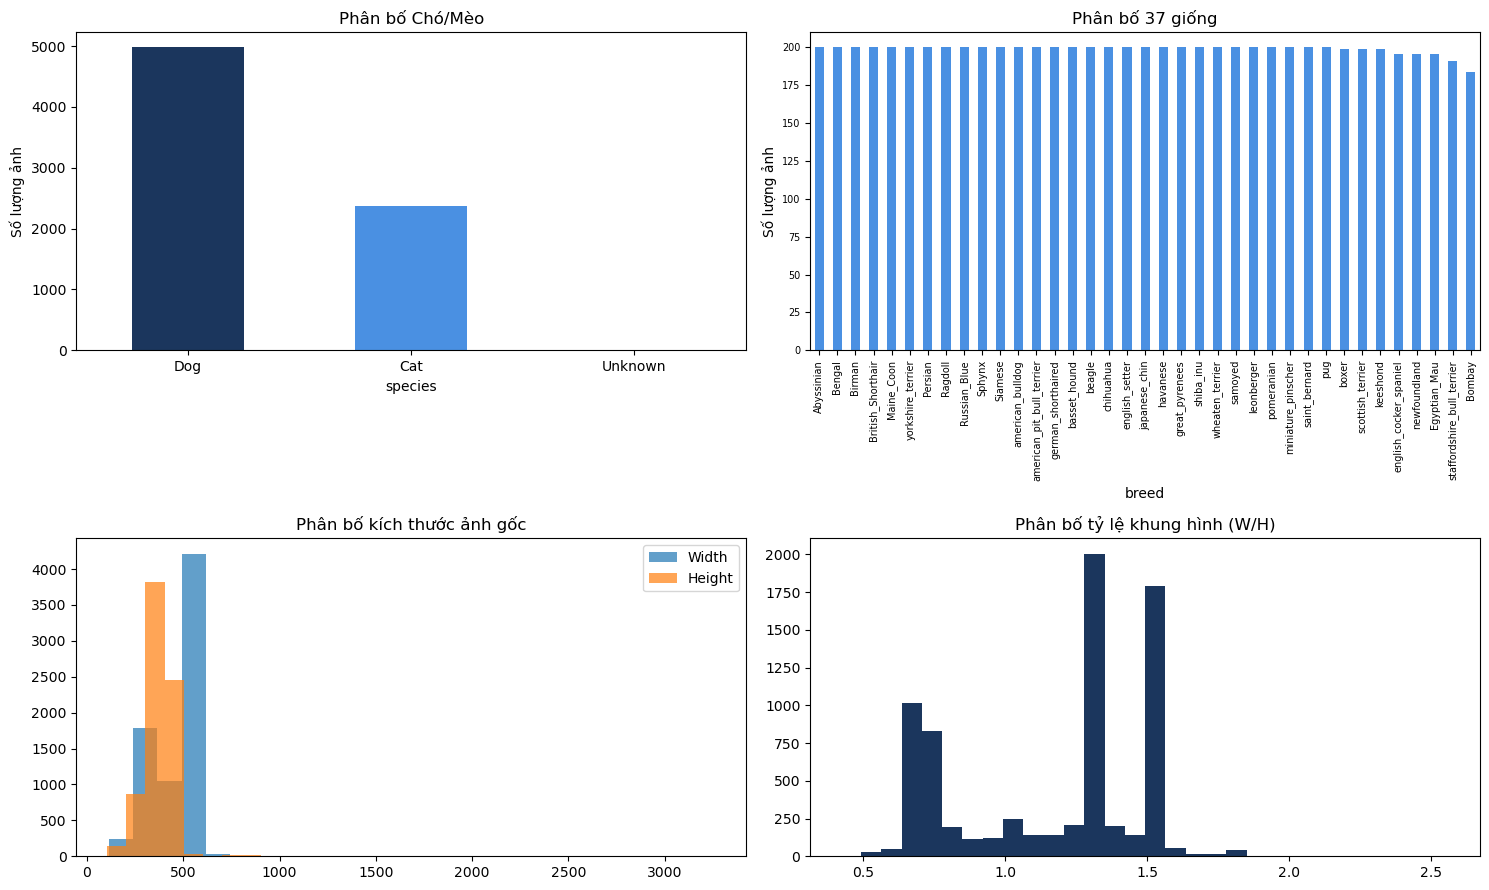

wandb: WARNING Artifact "data_quality_report" already exists with the same content. No new version will be created.


anomaly_total,▁
corrupted_count,▁
duplicate_count,▁
duplicate_need_review,▁
missing_masks,▁
non_rgb_count,▁
num_breeds,▁
orphan_masks,▁
raw_total,▁
valid_images,▁
anomaly_total,30


[W&B] Hoàn thành Run: R2_quality


In [4]:
# %% [Cell 2] Bước 2: Data Quality Check

import glob
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError

# ==========================================================
# Species Mapping từ list.txt
# ==========================================================

species_map = {}

list_txt_candidates = glob.glob(
    os.path.join(RAW_DIR, "**", "list.txt"),
    recursive=True
)

if list_txt_candidates:

    with open(list_txt_candidates[0], "r", encoding="utf-8") as f:

        for line in f:

            if line.startswith("#"):
                continue

            if not line.strip():
                continue

            parts = line.strip().split()

            if len(parts) >= 3:

                image_id = parts[0]
                species_id = int(parts[2])

                species_map[image_id] = "Cat" if species_id == 1 else "Dog"

# ==========================================================
# Data Quality Check
# ==========================================================

valid_records = []
anomalies = []
md5_registry = {}


def add_anomaly(file, type_, action, same_mask="N/A", same_breed="N/A"):
    anomalies.append({
        "file": file,
        "type": type_,
        "action": action,
        "same_mask": same_mask,
        "same_breed": same_breed
    })


# ------------------------------------------------------
# [THÊM] Mask mồ côi (có .png nhưng không có .jpg)
# ------------------------------------------------------

jpg_stems = {os.path.splitext(f)[0] for f in jpg_files}

for png_name in png_files:
    if os.path.splitext(png_name)[0] not in jpg_stems:
        add_anomaly(png_name, "Orphan_Mask", "Excluded")

for jpg_name in jpg_files:

    stem = os.path.splitext(jpg_name)[0]

    img_path = os.path.join(IMAGES_DIR, jpg_name)

    mask_path = os.path.join(TRIMAPS_DIR, f"{stem}.png")

    # ------------------------------------------------------
    # Missing Mask Check
    # ------------------------------------------------------

    if not os.path.exists(mask_path):

        add_anomaly(jpg_name, "Missing_Mask", "Removed")

        continue

    try:

        # --------------------------------------------------
        # Corrupted File Check
        # --------------------------------------------------

        with Image.open(img_path) as im:
            im.verify()

        with Image.open(mask_path) as mk:
            mk.verify()

        with Image.open(img_path) as im:

            orig_mode = im.mode
            w, h = im.size

            # ----------------------------------------------
            # RGB Check
            # [SỬA] Chỉ chuyển RGB trong bộ nhớ, KHÔNG ghi đè file raw
            # ----------------------------------------------

            if orig_mode != "RGB":

                add_anomaly(
                    jpg_name,
                    f"Mode_{orig_mode}",
                    "Converted_to_RGB_at_load"
                )

                im = im.convert("RGB")

            # ----------------------------------------------
            # Duplicate Check
            # [SỬA] Log cả cặp trùng, so sánh mask và giống
            # ----------------------------------------------

            digest = hashlib.md5(
                im.tobytes() + str(im.size).encode()
            ).hexdigest()

            if digest in md5_registry:

                first = md5_registry[digest]

                first_mask_path = os.path.join(
                    TRIMAPS_DIR,
                    os.path.splitext(first)[0] + ".png"
                )

                with Image.open(first_mask_path) as m1_img, Image.open(mask_path) as m2_img:
                    m1 = np.array(m1_img)
                    m2 = np.array(m2_img)

                same_mask = bool(m1.shape == m2.shape and (m1 == m2).all())

                same_breed = (
                    os.path.splitext(first)[0].rsplit("_", 1)[0]
                    == stem.rsplit("_", 1)[0]
                )

                # Mọi ảnh trùng pixel đều bị loại để không rò rỉ giữa train/val/test.
                # same_mask / same_breed chỉ để ghi nhận: nếu False thì nên xem tay.
                add_anomaly(
                    jpg_name,
                    f"Duplicate_of_{first}",
                    "Excluded",
                    same_mask=same_mask,
                    same_breed=same_breed
                )

                continue

            else:

                md5_registry[digest] = jpg_name

        breed = "_".join(stem.split("_")[:-1])

        species = species_map.get(stem, "Unknown")

        valid_records.append({

            "stem": stem,

            "img_path": img_path,

            "mask_path": mask_path,

            "breed": breed,

            "species": species,

            "width": w,

            "height": h,

            "aspect_ratio": round(w / h, 3),

            "orig_mode": orig_mode

        })

    except (UnidentifiedImageError, OSError) as err:

        add_anomaly(jpg_name, f"Corrupted: {err}", "Removed")

# ==========================================================
# DataFrame
# ==========================================================

df_eda = pd.DataFrame(valid_records)

# ==========================================================
# Summary Statistics
# ==========================================================

missing_masks = sum(1 for x in anomalies if x["type"] == "Missing_Mask")

orphan_masks = sum(1 for x in anomalies if x["type"] == "Orphan_Mask")

duplicate_count = sum(1 for x in anomalies if "Duplicate_of" in x["type"])

# Ảnh trùng khác mask hoặc khác giống: vẫn bị loại, nhưng nên xem tay
review_count = sum(
    1 for x in anomalies
    if "Duplicate_of" in x["type"]
    and (x["same_mask"] is False or x["same_breed"] is False)
)

raw_total = len(jpg_files)

corrupted_count = sum(1 for x in anomalies if "Corrupted" in x["type"])

# [SỬA] Tách đếm theo từng mode thay vì gộp chung thành rgba_count
mode_counts = (
    pd.Series([x["type"] for x in anomalies if x["type"].startswith("Mode_")])
    .value_counts()
    .to_dict()
)

non_rgb_count = int(sum(mode_counts.values()))

# ==========================================================
# Trimap Validation
# ==========================================================

unique_trimap_vals = set()

for m_path in df_eda["mask_path"]:

    with Image.open(m_path) as m_img:
        m_arr = np.array(m_img)

    unique_trimap_vals.update(np.unique(m_arr).tolist())

assert unique_trimap_vals == {1, 2, 3}, (
    f"Unexpected trimap labels: {unique_trimap_vals}"
)

print("Trimap labels:", sorted(list(unique_trimap_vals)))

print(f"Ảnh gốc (thô): {raw_total} -> hợp lệ sau lọc: {len(df_eda)}")

print(
    f"Hợp lệ: {len(df_eda)} | "
    f"Ngoại lệ phát hiện: {len(anomalies)} | "
    f"Số giống loài: {df_eda['breed'].nunique()}"
)

print(
    f"Thiếu mask: {missing_masks} | Mask mồ côi: {orphan_masks} | "
    f"Hỏng: {corrupted_count} | Trùng: {duplicate_count} (cần xem tay: {review_count}) | "
    f"Không phải RGB: {mode_counts if mode_counts else 0}"
)

if anomalies:

    anomaly_preview = pd.DataFrame(anomalies)

    print(anomaly_preview.head(10))

    dup_df = anomaly_preview[anomaly_preview["type"].str.startswith("Duplicate_of")]

    if len(dup_df):
        print(
            "Cặp trùng có cùng mask:", int((dup_df["same_mask"] == True).sum()),
            "/", len(dup_df),
            "| cùng giống:", int((dup_df["same_breed"] == True).sum()),
            "/", len(dup_df)
        )

# ==========================================================
# [THÊM] Danh sách ảnh bị loại -> dùng lại ở Bước 7 và báo cáo
# ==========================================================

EXCLUDED_PATH = "data/splits/excluded.txt"

with open(EXCLUDED_PATH, "w", encoding="utf-8") as f:
    f.write("\n".join(
        x["file"] for x in anomalies
        if x["action"] in ("Excluded", "Removed")
    ))

# ==========================================================
# Dataset Statistics Figure
# [SỬA] Đúng tên dataset_statistics.png, thêm 37 giống + tỷ lệ khung hình
# ==========================================================

DATASET_STATS_PATH = "results/figures/dataset_statistics.png"

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

df_eda["species"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color=["#1B365D", "#4A90E2"], rot=0
)
axes[0, 0].set_title("Phân bố Chó/Mèo")
axes[0, 0].set_ylabel("Số lượng ảnh")

df_eda["breed"].value_counts().plot(
    kind="bar", ax=axes[0, 1], color="#4A90E2", fontsize=7
)
axes[0, 1].set_title("Phân bố 37 giống")
axes[0, 1].set_ylabel("Số lượng ảnh")

axes[1, 0].hist(df_eda["width"], bins=25, alpha=0.7, label="Width")
axes[1, 0].hist(df_eda["height"], bins=25, alpha=0.7, label="Height")
axes[1, 0].set_title("Phân bố kích thước ảnh gốc")
axes[1, 0].legend()

axes[1, 1].hist(df_eda["aspect_ratio"], bins=30, color="#1B365D")
axes[1, 1].set_title("Phân bố tỷ lệ khung hình (W/H)")

plt.tight_layout()

plt.savefig(DATASET_STATS_PATH, dpi=300)

plt.show()

# ==========================================================
# W&B Run 02
# ==========================================================

run_quality = wandb.init(

    project="Oxford-IIIT-Pet-Segmentation",

    entity=WANDB_ENTITY,

    name="R2_quality",

    job_type="EDA",

    tags=["TV1", "quality", f"data_version:{CONFIG['data_version']}"],

    config={

        **CONFIG,

        "log_id": "P002",

        "work_item": "Data Quality Check",

        "target_file": "data/raw",

        "handoff_status": "Completed"

    },

    notes=(
        "Kiểm tra dữ liệu: missing mask, orphan mask, corrupted image, "
        "ảnh không phải RGB (chuyển RGB lúc đọc, không ghi đè raw), "
        "ảnh trùng lặp, trimap labels."
    ),

    reinit="finish_previous"

)

# ==========================================================
# Metrics
# ==========================================================

run_quality.log({

    "valid_images": len(df_eda),

    "num_breeds": int(df_eda["breed"].nunique()),

    "missing_masks": missing_masks,

    "orphan_masks": orphan_masks,

    "non_rgb_count": non_rgb_count,

    "duplicate_count": duplicate_count,

    "corrupted_count": corrupted_count,

    "anomaly_total": len(anomalies),

    "duplicate_need_review": review_count,

    "raw_total": raw_total,

    "dataset_statistics": wandb.Image(DATASET_STATS_PATH)

})

# [SỬA] Không log n_train/n_val/n_test/overlap_count = 0 ở run chưa chia tập.
# decision / reason đưa vào summary.
run_quality.summary.update({

    "trimap_unique_labels": str(sorted(list(unique_trimap_vals))),

    "non_rgb_by_mode": str(mode_counts),

    "decision": "ACCEPT",

    "reason": (
        "Dataset đạt yêu cầu sau kiểm tra; ảnh trùng được loại, "
        "ảnh không phải RGB sẽ chuyển RGB khi đọc."
    )

})

# ==========================================================
# Tables
# ==========================================================

if anomalies:

    anomaly_df = pd.DataFrame(anomalies).astype(str)

    run_quality.log({
        "anomaly_table": wandb.Table(dataframe=anomaly_df)
    })

breed_df = (
    df_eda.groupby(["breed", "species"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

run_quality.log({
    "breed_table": wandb.Table(dataframe=breed_df)
})

# ==========================================================
# Artifact
# ==========================================================

artifact = wandb.Artifact(

    name="data_quality_report",

    type="quality_check"

)

artifact.add_file("data/splits/split_config.json")

artifact.add_file(DATASET_STATS_PATH)

artifact.add_file(EXCLUDED_PATH)

run_quality.log_artifact(artifact)

run_quality.finish()

print("[W&B] Hoàn thành Run: R2_quality")

# Bước 3 & 4: Giải mã Trimap và Border Policy (Gate 1)
- Trimap Oxford-IIIT Pet: **1 = Foreground (Pet)**, **2 = Background (Nền)**, **3 = Not classified / Border (Vùng biên)**.
- So sánh 3 phương án: (a) biên → Pet, (b) biên → Background, (c) `ignore_index`. Chọn theo quan sát và lập luận, **không** chọn theo mIoU.

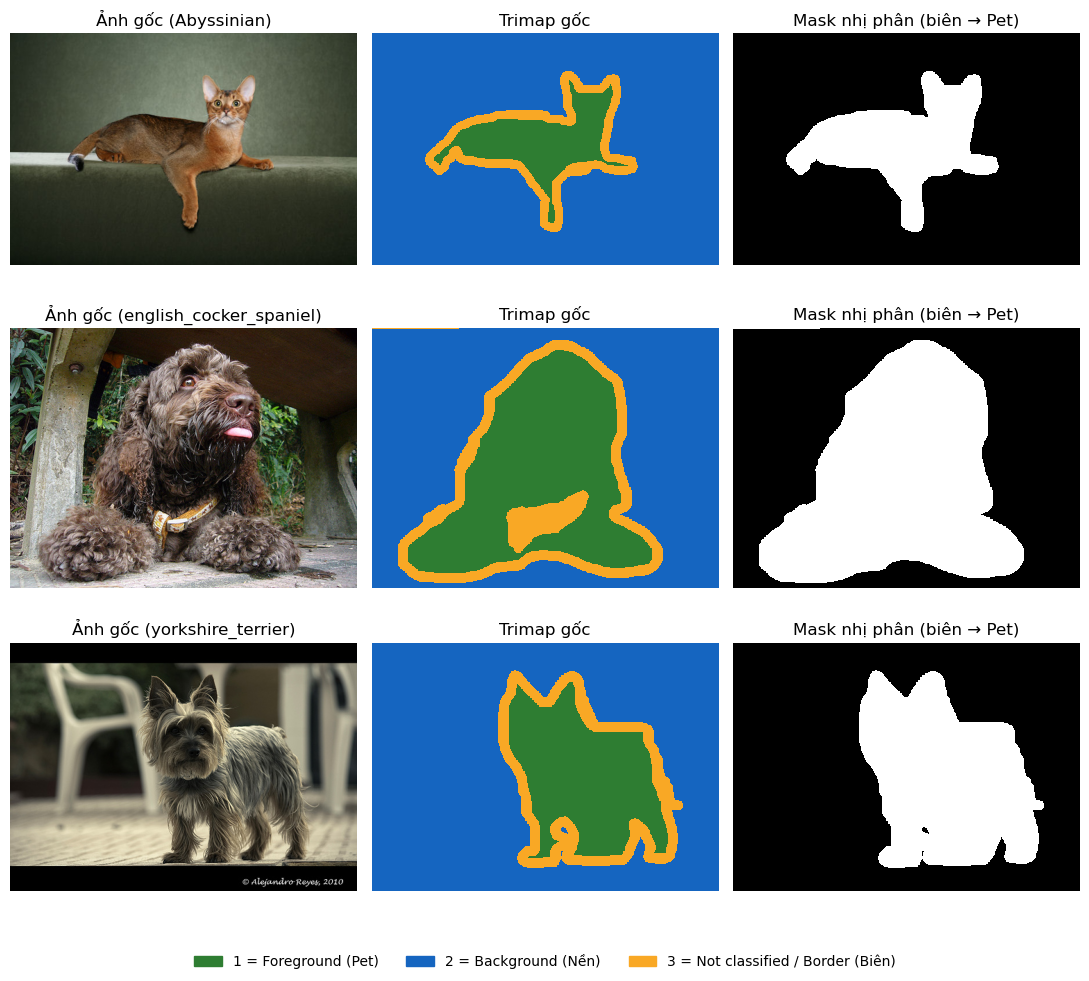

[Bước 4] Tỷ lệ pixel theo nhãn trimap (toàn dataset):
{
  "pct_label1_pet": 29.499,
  "pct_label2_bg": 58.928,
  "pct_label3_border": 11.573,
  "mean_border_share_of_pet_mask_pct": 31.595
}
             Phương án                                                  Quan sát Quyết định                                                                                          Lý do
        (a) Biên → Pet                                 Mask ôm sát lông, hơi dày       Chọn Giữ vùng viền lông trong vùng cần dự đoán; đầu ra 2 lớp khớp E4; không phải sửa metric của TV2
 (b) Biên → Background                                        Mất phần lông mảnh       Loại                                                       Mất phần lông mảnh khỏi vùng cần dự đoán
(c) ignore_index = 255 Phải sửa loss và metric của TV2, nhãn có thêm giá trị 255       Loại                                        Phải sửa hàm loss/metric của TV2 và xử lý thêm nhãn 255


mean_border_share_of_pet_mask_pct,▁
num_breeds,▁
pct_label1_pet,▁
pct_label2_bg,▁
pct_label3_border,▁
valid_images,▁
decision,PROPOSED
mean_border_share_of_pet_mask_pct,31.595
num_breeds,37
pct_label1_pet,29.499
pct_label2_bg,58.928


[W&B] Hoàn thành Run: R3_border_policy


In [5]:
# %% [Cell 3] Bước 3 & 4: Trimap & Border Policy Decision (Gate 1)

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ==========================================================
# Bước 3: Ảnh gốc -> Trimap gốc -> Mask nhị phân (có chú giải)
# ==========================================================

TRIMAP_COLORS = ["#2E7D32", "#1565C0", "#F9A825"]  # 1 = Pet, 2 = Nền, 3 = Biên
trimap_cmap = ListedColormap(TRIMAP_COLORS)

fig, axes = plt.subplots(3, 3, figsize=(11, 10))

sample_indices = [0, len(df_eda) // 2, len(df_eda) - 1]

for r_idx, sample_idx in enumerate(sample_indices):

    row = df_eda.iloc[sample_idx]

    image = Image.open(row["img_path"]).convert("RGB")

    with Image.open(row["mask_path"]) as m_img:
        trimap = np.array(m_img)

    binary_mask = np.where((trimap == 1) | (trimap == 3), 1, 0)

    axes[r_idx, 0].imshow(image)
    axes[r_idx, 0].set_title(f"Ảnh gốc ({row['breed']})")
    axes[r_idx, 0].axis("off")

    axes[r_idx, 1].imshow(trimap, cmap=trimap_cmap, vmin=1, vmax=3, interpolation="nearest")
    axes[r_idx, 1].set_title("Trimap gốc")
    axes[r_idx, 1].axis("off")

    axes[r_idx, 2].imshow(binary_mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[r_idx, 2].set_title("Mask nhị phân (biên → Pet)")
    axes[r_idx, 2].axis("off")

# [THÊM] Chú giải ý nghĩa nhãn trimap
fig.legend(
    handles=[
        Patch(color=TRIMAP_COLORS[0], label="1 = Foreground (Pet)"),
        Patch(color=TRIMAP_COLORS[1], label="2 = Background (Nền)"),
        Patch(color=TRIMAP_COLORS[2], label="3 = Not classified / Border (Biên)"),
    ],
    loc="lower center", ncol=3, frameon=False
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

MASK_EXAMPLE_PATH = "results/figures/mask_examples.png"

plt.savefig(MASK_EXAMPLE_PATH, dpi=300, bbox_inches="tight")

plt.show()

# ==========================================================
# Bước 4: 3 phiên bản mask cho 20 ảnh mẫu + overlay cạnh nhau
# ==========================================================

def make_variants(tri):
    a = np.where((tri == 1) | (tri == 3), 1, 0)                 # (a) biên -> Pet
    b = np.where(tri == 1, 1, 0)                                # (b) biên -> Background
    c = np.where(tri == 1, 1, np.where(tri == 2, 0, 255))       # (c) ignore_index = 255
    return a, b, c


def overlay(img, m):
    out = np.array(img).astype(float)
    pet = m == 1
    ign = m == 255
    out[pet] = out[pet] * 0.5 + np.array([255, 0, 0]) * 0.5     # Pet: đỏ
    out[ign] = out[ign] * 0.5 + np.array([255, 255, 0]) * 0.5   # ignore: vàng
    return out.astype(np.uint8)


rng = np.random.default_rng(CONFIG["seed"])
sample_df = df_eda.iloc[rng.choice(len(df_eda), 20, replace=False)]

col_titles = ["Ảnh gốc", "(a) Biên → Pet", "(b) Biên → Background", "(c) ignore_index (vàng)"]

sample_rows = list(sample_df.iterrows())

OVERLAY_PATHS = []

# Tách 2 ảnh x 10 hàng để dễ đọc và dễ chèn vào báo cáo; dpi=120 để thấy rõ viền lông
for part in range(2):

    fig, axes = plt.subplots(10, 4, figsize=(10, 25))

    for r, (_, row) in enumerate(sample_rows[part * 10:(part + 1) * 10]):

        img = Image.open(row["img_path"]).convert("RGB")

        with Image.open(row["mask_path"]) as m_img:
            tri = np.array(m_img)

        a, b, c = make_variants(tri)

        panels = [np.array(img), overlay(img, a), overlay(img, b), overlay(img, c)]

        for k, panel in enumerate(panels):
            axes[r, k].imshow(panel)
            axes[r, k].axis("off")
            if r == 0:
                axes[r, k].set_title(col_titles[k])

    plt.tight_layout()

    path = f"results/figures/border_policy_overlay_part{part + 1}.png"

    plt.savefig(path, dpi=120)

    plt.close()

    OVERLAY_PATHS.append(path)

# ==========================================================
# Đo tỷ lệ pixel nhãn 3 trên TOÀN BỘ dataset
# ==========================================================

label_counts = np.zeros(4, dtype=np.int64)
border_share_of_pet = []

for p in df_eda["mask_path"]:

    with Image.open(p) as m_img:
        t = np.array(m_img)

    bc = np.bincount(t.ravel(), minlength=4)

    label_counts += bc

    # Phần diện tích Pet của phương án (a) đến từ vùng biên (proxy cho độ "dày" của mask)
    border_share_of_pet.append(bc[3] / max(bc[1] + bc[3], 1))

total_px = int(label_counts.sum())

border_stats = {
    "pct_label1_pet": round(label_counts[1] / total_px * 100, 3),
    "pct_label2_bg": round(label_counts[2] / total_px * 100, 3),
    "pct_label3_border": round(label_counts[3] / total_px * 100, 3),
    "mean_border_share_of_pet_mask_pct": round(float(np.mean(border_share_of_pet)) * 100, 3),
}

print("[Bước 4] Tỷ lệ pixel theo nhãn trimap (toàn dataset):")
print(json.dumps(border_stats, indent=2, ensure_ascii=False))

# ==========================================================
# Bảng quyết định
# [QUAN TRỌNG] Sửa cột "Quan sát" cho đúng với những gì bạn thấy trong
# border_policy_overlay.png trước khi chạy tiếp.
# ==========================================================

OBS_A = "Mask ôm sát lông, hơi dày"
OBS_B = "Mất phần lông mảnh"
OBS_C = "Phải sửa loss và metric của TV2, nhãn có thêm giá trị 255"

decision_df = pd.DataFrame([
    {
        "Phương án": "(a) Biên → Pet",
        "Quan sát": OBS_A,
        "Quyết định": "Chọn",
        "Lý do": "Giữ vùng viền lông trong vùng cần dự đoán; đầu ra 2 lớp khớp E4; không phải sửa metric của TV2"
    },
    {
        "Phương án": "(b) Biên → Background",
        "Quan sát": OBS_B,
        "Quyết định": "Loại",
        "Lý do": "Mất phần lông mảnh khỏi vùng cần dự đoán"
    },
    {
        "Phương án": "(c) ignore_index = 255",
        "Quan sát": OBS_C,
        "Quyết định": "Loại",
        "Lý do": "Phải sửa hàm loss/metric của TV2 và xử lý thêm nhãn 255"
    },
])

print(decision_df.to_string(index=False))

# ==========================================================
# Ghi nhận Gate 1 (chỉ đặt True SAU KHI đã họp chốt với TV2, TV3)
# ==========================================================

GATE1_CONFIRMED = False
GATE1_DATE = "<điền ngày họp Gate 1>"
GATE1_ATTENDEES = ["TV1", "TV2", "TV3"]

# ==========================================================
# W&B Run 03
# ==========================================================

run_policy = wandb.init(

    project="Oxford-IIIT-Pet-Segmentation",

    entity=WANDB_ENTITY,

    name="R3_border_policy",

    job_type="EDA",

    tags=["TV1", "policy", f"data_version:{CONFIG['data_version']}"],

    config={

        **CONFIG,

        # Excel Log
        "log_id": "P003",

        "work_item": "Border Policy Decision",

        "target_file": "preprocessing.py",

        "handoff_status": "Completed" if GATE1_CONFIRMED else "Pending_Gate1",

        "gate1_date": GATE1_DATE,

        "gate1_attendees": GATE1_ATTENDEES,

        "n_overlay_samples": 20

    },

    notes=(
        "Gate 1: đề xuất phương án (a): Pet={1,3}->1, Background={2}->0. "
        "Chọn theo quan sát overlay + lập luận, không chọn theo mIoU. "
        "Hạn chế: mask hơi dày hơn thực tế nên IoU có thể cao nhẹ."
    ),

    reinit="finish_previous"

)

run_policy.log({

    "valid_images": len(df_eda),

    "num_breeds": int(df_eda["breed"].nunique()),

    **border_stats,

    "border_overlay_1": wandb.Image(OVERLAY_PATHS[0]),

    "border_overlay_2": wandb.Image(OVERLAY_PATHS[1]),

    "mask_examples": wandb.Image(MASK_EXAMPLE_PATH),

    "decision_table": wandb.Table(dataframe=decision_df)

})

run_policy.summary.update({

    "policy_name": "A",

    "policy_pet_labels": "[1,3]",

    "policy_background_labels": "[2]",

    "policy_status": "LOCKED" if GATE1_CONFIRMED else "PROPOSED_PENDING_GATE1",

    "decision": "APPROVED" if GATE1_CONFIRMED else "PROPOSED",

    "reason": (
        "Giữ vùng biên lông trong vùng cần dự đoán. "
        "Đầu ra nhị phân phù hợp với pipeline TV2 và không cần sửa metric đánh giá. "
        "Hạn chế: mask dày hơn thực tế nên IoU có thể cao nhẹ."
    )

})

# ==========================================================
# Artifact
# ==========================================================

artifact = wandb.Artifact(

    name="border_policy_decision",

    type="policy"

)

artifact.add_file(MASK_EXAMPLE_PATH)

for _p in OVERLAY_PATHS:
    artifact.add_file(_p)

run_policy.log_artifact(artifact)

run_policy.finish()

print("[W&B] Hoàn thành Run: R3_border_policy")